<img src=https://i.imgur.com/WKQ0nH2.jpg height=350>

# Setup and Context


### Introduction

Welcome to Boston Massachusetts in the 1970s! Imagine you're working for a real estate development company. Your company wants to value any residential project before they start. You are tasked with building a model that can provide a price estimate based on a home's characteristics like:
* The number of rooms
* The distance to employment centres
* How rich or poor the area is
* How many students there are per teacher in local schools etc

<img src=https://i.imgur.com/WfUSSP7.png height=350>

To accomplish your task you will:

1. Analyse and explore the Boston house price data
2. Split your data for training and testing
3. Run a Multivariable Regression
4. Evaluate how your model's coefficients and residuals
5. Use data transformation to improve your model performance
6. Use your model to estimate a property price

### Upgrade plotly (only Google Colab Notebook)

Google Colab may not be running the latest version of plotly. If you're working in Google Colab, uncomment the line below, run the cell, and restart your notebook server. 

In [ ]:
# %pip install --upgrade plotly

###  Import Statements


In [32]:
import pandas as pd
import numpy as np

import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

### Notebook Presentation

In [3]:
pd.options.display.float_format = '{:,.2f}'.format

# Load the Data

The first column in the .csv file just has the row numbers, so it will be used as the index. 

In [4]:
data = pd.read_csv('boston.csv', index_col=0)

### Understand the Boston House Price Dataset

---------------------------

**Characteristics:**  

    :Number of Instances: 506 

    :Number of Attributes: 13 numeric/categorical predictive. The Median Value (attribute 14) is the target.

    :Attribute Information (in order):
        1. CRIM     per capita crime rate by town
        2. ZN       proportion of residential land zoned for lots over 25,000 sq.ft.
        3. INDUS    proportion of non-retail business acres per town
        4. CHAS     Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
        5. NOX      nitric oxides concentration (parts per 10 million)
        6. RM       average number of rooms per dwelling
        7. AGE      proportion of owner-occupied units built prior to 1940
        8. DIS      weighted distances to five Boston employment centres
        9. RAD      index of accessibility to radial highways
        10. TAX      full-value property-tax rate per $10,000
        11. PTRATIO  pupil-teacher ratio by town
        12. B        1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town
        13. LSTAT    % lower status of the population
        14. PRICE     Median value of owner-occupied homes in $1000's
        
    :Missing Attribute Values: None

    :Creator: Harrison, D. and Rubinfeld, D.L.

This is a copy of [UCI ML housing dataset](https://archive.ics.uci.edu/ml/machine-learning-databases/housing/). This dataset was taken from the StatLib library which is maintained at Carnegie Mellon University. You can find the [original research paper here](https://deepblue.lib.umich.edu/bitstream/handle/2027.42/22636/0000186.pdf?sequence=1&isAllowed=y). 


# Preliminary Data Exploration 🔎

**Challenge**

* What is the shape of `data`? 
* How many rows and columns does it have?
* What are the column names?
* Are there any NaN values or duplicates?

In [5]:
print(f"Rows and columns: {data.shape}")

Rows and columns: (506, 14)


In [6]:
data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.01,18.00,2.31,0.00,0.54,6.58,65.20,4.09,1.00,296.00,15.30,396.90,4.98,24.00
1,0.03,0.00,7.07,0.00,0.47,6.42,78.90,4.97,2.00,242.00,17.80,396.90,9.14,21.60
2,0.03,0.00,7.07,0.00,0.47,7.18,61.10,4.97,2.00,242.00,17.80,392.83,4.03,34.70
3,0.03,0.00,2.18,0.00,0.46,7.00,45.80,6.06,3.00,222.00,18.70,394.63,2.94,33.40
4,0.07,0.00,2.18,0.00,0.46,7.15,54.20,6.06,3.00,222.00,18.70,396.90,5.33,36.20


## Data Cleaning - Check for Missing Values and Duplicates

In [7]:
nan_values = data.isna().sum().sum()

In [8]:
duplicated_values = data.duplicated().sum()

In [9]:
print(f"There are {nan_values} NaN values and {duplicated_values} duplicated values")

There are 0 NaN values and 0 duplicated values


## Descriptive Statistics

**Challenge**

* How many students are there per teacher on average?
* What is the average price of a home in the dataset?
* What is the `CHAS` feature? 
* What are the minimum and the maximum value of the `CHAS` and why?
* What is the maximum and the minimum number of rooms per dwelling in the dataset?

In [10]:
print(f"There are {data.PTRATIO.mean():.4} students per teacher on average.")

There are 18.46 students per teacher on average.


In [11]:
# Describe the whole data set and get answers, I'll still print them for more clarity in the next cell
data.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
count,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00
mean,3.61,11.36,11.14,0.07,0.55,6.28,68.57,3.80,9.55,408.24,18.46,356.67,12.65,22.53
std,8.60,23.32,6.86,0.25,0.12,0.70,28.15,2.11,8.71,168.54,2.16,91.29,7.14,9.20
min,0.01,0.00,0.46,0.00,0.39,3.56,2.90,1.13,1.00,187.00,12.60,0.32,1.73,5.00
25%,0.08,0.00,5.19,0.00,0.45,5.89,45.02,2.10,4.00,279.00,17.40,375.38,6.95,17.02
50%,0.26,0.00,9.69,0.00,0.54,6.21,77.50,3.21,5.00,330.00,19.05,391.44,11.36,21.20
75%,3.68,12.50,18.10,0.00,0.62,6.62,94.07,5.19,24.00,666.00,20.20,396.23,16.96,25.00
max,88.98,100.00,27.74,1.00,0.87,8.78,100.00,12.13,24.00,711.00,22.00,396.90,37.97,50.00


In [12]:
print(f"The average price of a home in the dataset is: {data.PRICE.mean():.4}")
print(f"The minimum CHAS value is: {data.CHAS.min():.4}, and the maximum CHAS value is: {data.CHAS.max():.4}")
print(f"The minimum number of rooms per dwelling is: {data.RM.min():.4}, the maximum number of rooms per dwelling is: {data.RM.max():.4}")

The average price of a home in the dataset is: 22.53
The minimum CHAS value is: 0.0, and the maximum CHAS value is: 1.0
The minimum number of rooms per dwelling is: 3.561, the maximum number of rooms per dwelling is: 8.78


## Visualise the Features

**Challenge**: Having looked at some descriptive statistics, visualise the data for your model. Use [Seaborn's `.displot()`](https://seaborn.pydata.org/generated/seaborn.displot.html#seaborn.displot) to create a bar chart and superimpose the Kernel Density Estimate (KDE) for the following variables: 
* PRICE: The home price in thousands.
* RM: the average number of rooms per owner unit.
* DIS: the weighted distance to the 5 Boston employment centres i.e., the estimated length of the commute.
* RAD: the index of accessibility to highways. 

Try setting the `aspect` parameter to `2` for a better picture. 

What do you notice in the distributions of the data? 

#### House Prices 💰

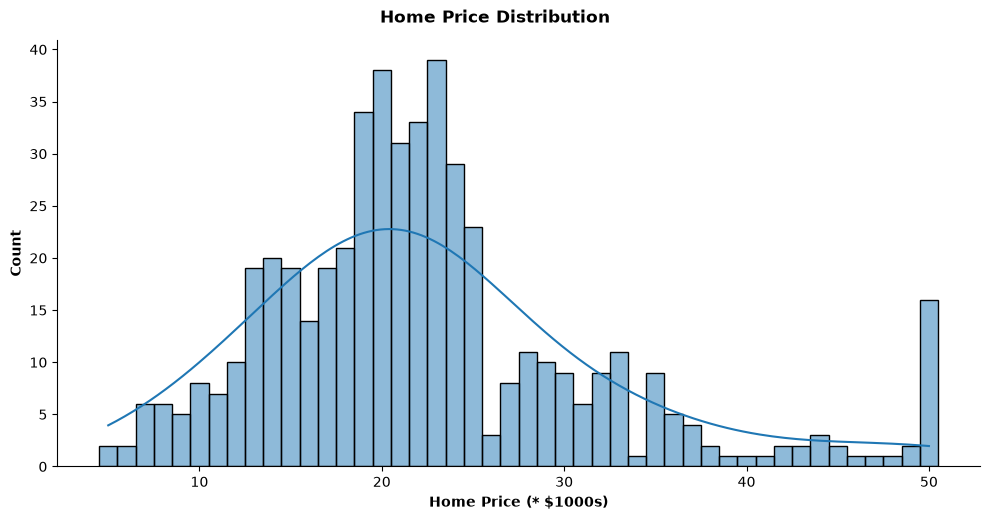

In [13]:
h_p = sns.displot(
    data=data,
    x="PRICE",
    discrete=True,
    kde=True,
    kde_kws={"bw_adjust": 2},
    aspect=2
)

h_p.figure.suptitle("Home Price Distribution", fontweight="bold", y=1.03)

h_p.set_axis_labels("Home Price (* $1000s)", "Count", fontweight="bold")

plt.show()

<p>The chart indicates that there are more homes on average that ranges in the $20,000s.</p>

#### Distance to Employment - Length of Commute 🚗

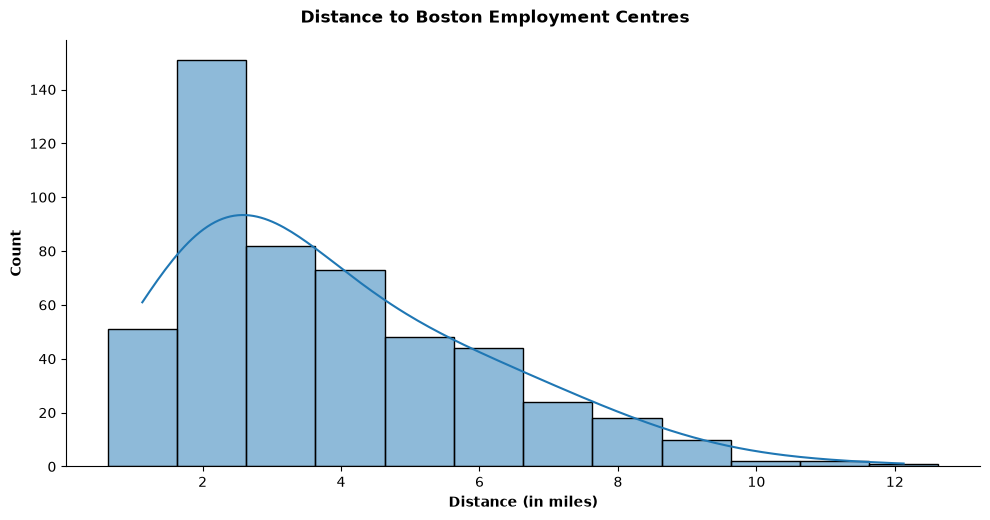

In [14]:
dis = sns.displot(
    data=data,
    x="DIS",
    discrete=True,
    kde=True,
    kde_kws={"bw_adjust": 2},
    aspect=2
)

dis.figure.suptitle("Distance to Boston Employment Centres", fontweight="bold", y=1.03)

dis.set_axis_labels("Distance (in miles)", "Count", fontweight="bold")

plt.show()

<p>The chart above indicates that there are more homes located 2 miles away from Boston employment centres. Which means more people live close to the commercial area.</p>

#### Number of Rooms

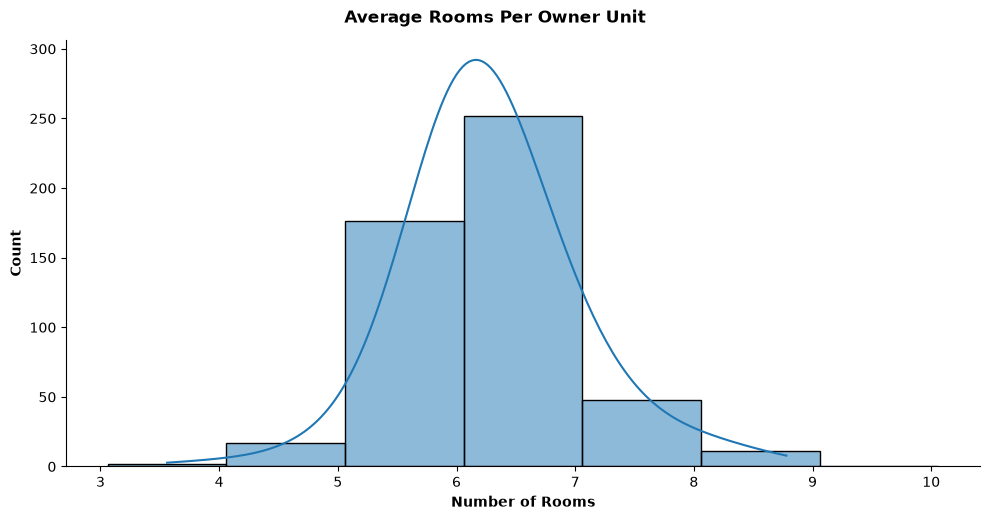

In [15]:
n_r = sns.displot(
    data=data,
    x="RM",
    discrete=True,
    kde=True,
    kde_kws={"bw_adjust": 2},
    aspect=2
)

n_r.figure.suptitle("Average Rooms Per Owner Unit", fontweight="bold", y=1.03)

n_r.set_axis_labels("Number of Rooms", "Count", fontweight="bold")

plt.show()

<p>We can see the chart peak at RM 6. This chart indicates that A majority of housing units average 6 rooms.</p>

#### Access to Highways 🛣

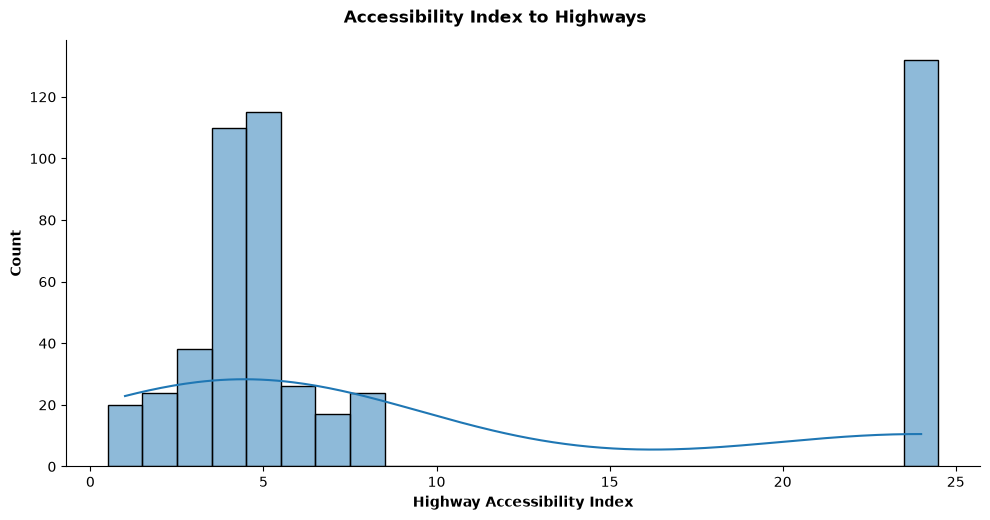

In [16]:
a_h = sns.displot(
    data=data,
    x="RAD",
    discrete=True,
    kde=True,
    kde_kws={"bw_adjust": 2},
    aspect=2
)

a_h.figure.suptitle("Accessibility Index to Highways", fontweight="bold", y=1.03)

a_h.set_axis_labels("Highway Accessibility Index", "Count", fontweight="bold")

plt.show()

<p>There is a rather huge gap from 9-23 and a sharp peak at 24. There's a really sharp devide in how well accessibility to highways is rated.</p>

#### Next to the River? ⛵️

**Challenge**

Create a bar chart with plotly for CHAS to show many more homes are away from the river versus next to it. The bar chart should look something like this:

<img src=https://i.imgur.com/AHwoQ6l.png height=350>

You can make your life easier by providing a list of values for the x-axis (e.g., `x=['No', 'Yes']`)

In [17]:
chas_counts = data.CHAS.value_counts().reset_index()
chas_counts.columns = ["CHAS", 'Count']
chas_counts.CHAS = chas_counts.CHAS.map({0: "No", 1: "Yes"})

In [18]:
fig = px.bar(
    data_frame=chas_counts,
    x="CHAS",
    y="Count",
    color=chas_counts.CHAS.astype(str),
    title="<b>Homes Next to the River vs Homes Away From the River</b>"
)

fig.update_layout(title_x=0.5)

fig.show()

<p>This chart indicates that there are significantly higher amounts of homes that are located away from the river. There are over 400 homes located away from the river and less than 50 homes located next to the river.</p>

<img src=https://i.imgur.com/b5UaBal.jpg height=350>

# Understand the Relationships in the Data

### Run a Pair Plot

**Challenge**

There might be some relationships in the data that we should know about. Before you run the code, make some predictions:

* What would you expect the relationship to be between pollution (NOX) and the distance to employment (DIS)? 
* What kind of relationship do you expect between the number of rooms (RM) and the home value (PRICE)?
* What about the amount of poverty in an area (LSTAT) and home prices? 

Run a [Seaborn `.pairplot()`](https://seaborn.pydata.org/generated/seaborn.pairplot.html?highlight=pairplot#seaborn.pairplot) to visualise all the relationships at the same time. Note, this is a big task and can take 1-2 minutes! After it's finished check your intuition regarding the questions above on the `pairplot`. 

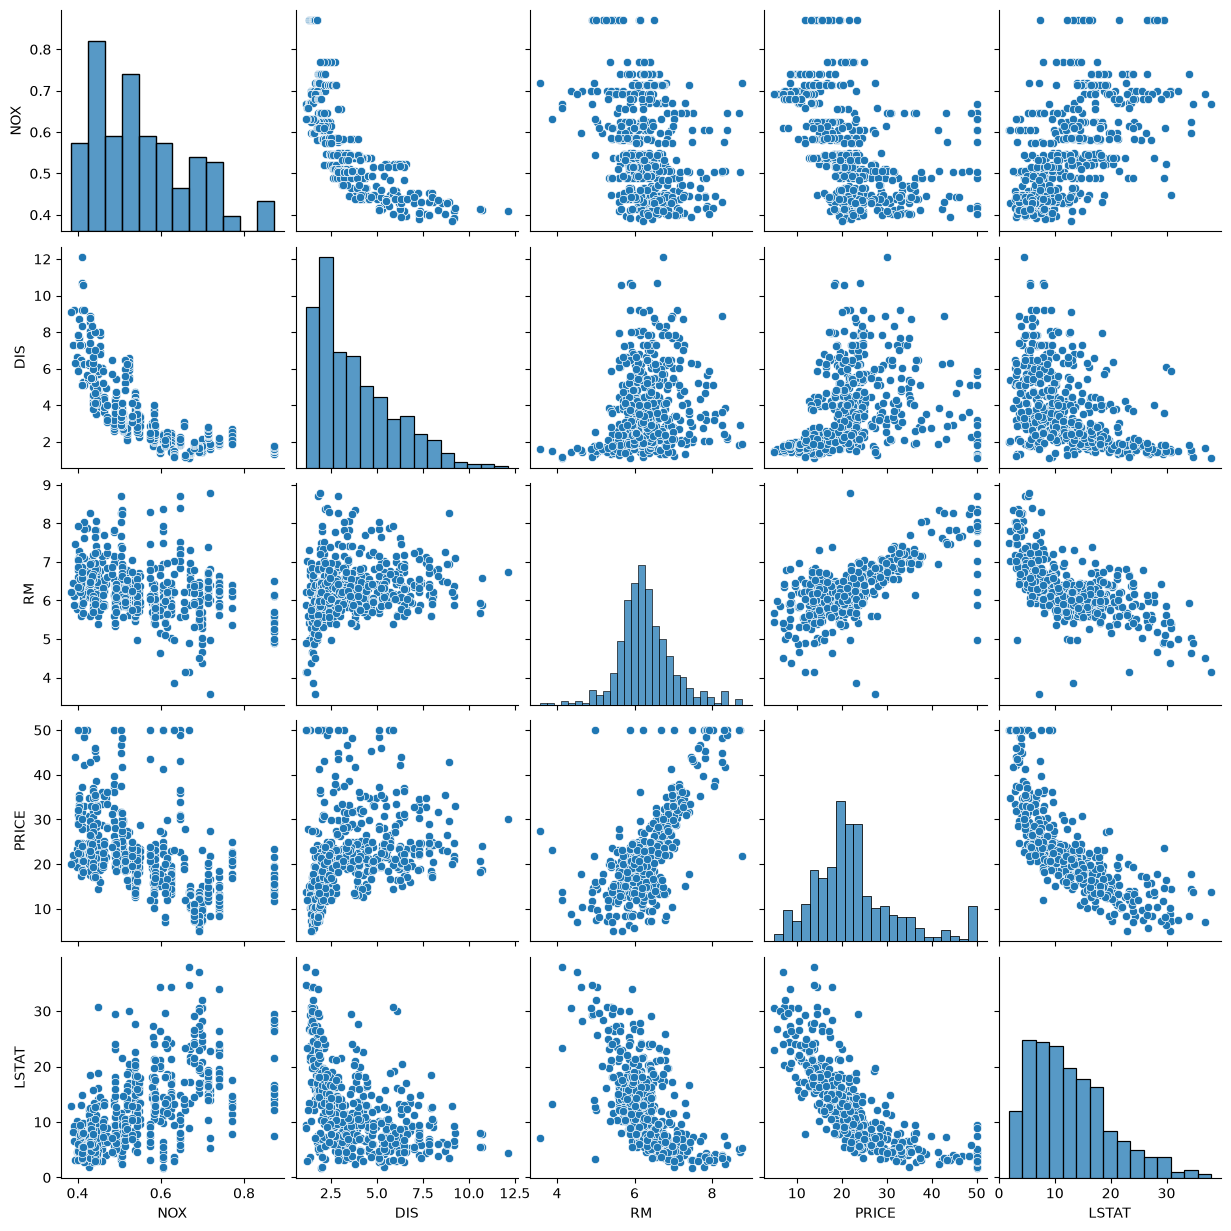

In [21]:
sns.pairplot(
    data=data,
    vars=["NOX", "DIS", "RM", "PRICE", "LSTAT"]
)

plt.show()

#### Observations
<ol>
<li> As expected, the closer the houses are to the employment centres, the more polluted they become. A commercial zone is more likely to be polluted than a residential one.</li>
<li> Also as expected, the higher the room numbers, the more expensive the house becomes. Houses with more space should generally have more value.</li>
<li> The results here aren't far fetched as well. The places with a higher density of people with socio-economic disadvantages have generally cheaper house prices. Individuals that fall into this category would naturally search for houses with lower value.</li>
</ol>

**Challenge**

Use [Seaborn's `.jointplot()`](https://seaborn.pydata.org/generated/seaborn.jointplot.html) to look at some of the relationships in more detail. Create a jointplot for:

* DIS and NOX
* INDUS vs NOX
* LSTAT vs RM
* LSTAT vs PRICE
* RM vs PRICE

Try adding some opacity or `alpha` to the scatter plots using keyword arguments under `joint_kws`.

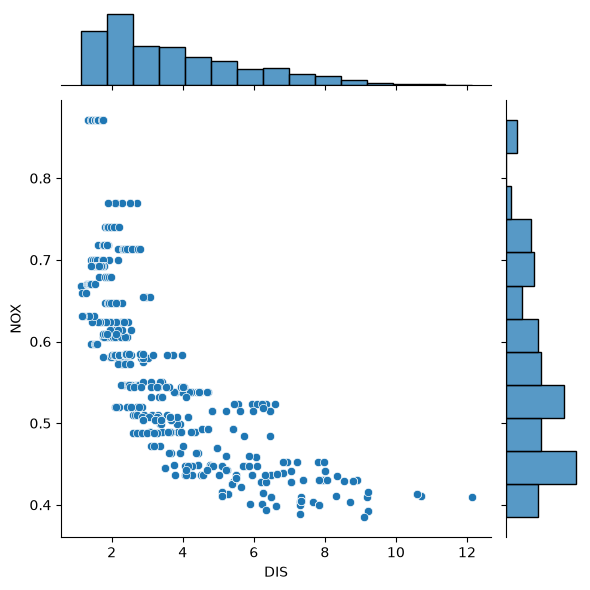

In [27]:
sns.jointplot(
    data=data,
    x="DIS",
    y="NOX",
)

plt.show()

#### Observations (DIS and NOX)
<ol>
<li>A higher percentage of homes are located 1-4 miles away from the Boston employment centers. Extremely few are located 8-10 miles away</li>
<li>Most houses are faced with low-average levels of polution between 0.4-0.5, while fewer houses are faced with extreme levels of polution.</li>
<li>The chart suggests that being closer to Bolton's employment centers (1-4) exposes you to higher polution levels (0.5-0.8)</li>
</ol>

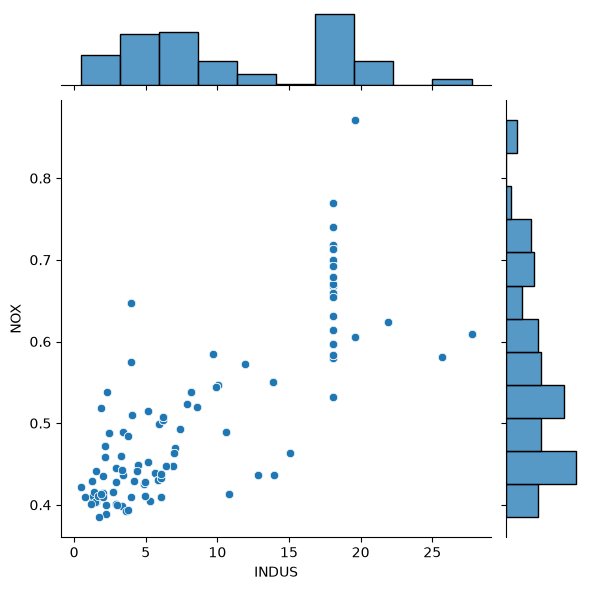

In [28]:
sns.jointplot(
    data=data,
    x="INDUS",
    y="NOX"
)

plt.show()

#### Observations (INDUX and NOX)
<ol>
<li>This chart indicates that lands with higher density of Industries tend to produce significantly higher air polution.</li>
<li>~18-25 will likely produce air polution of 0.55 and above. This is natural due to industrial activities going on at a larger scale.</li>
</ol>

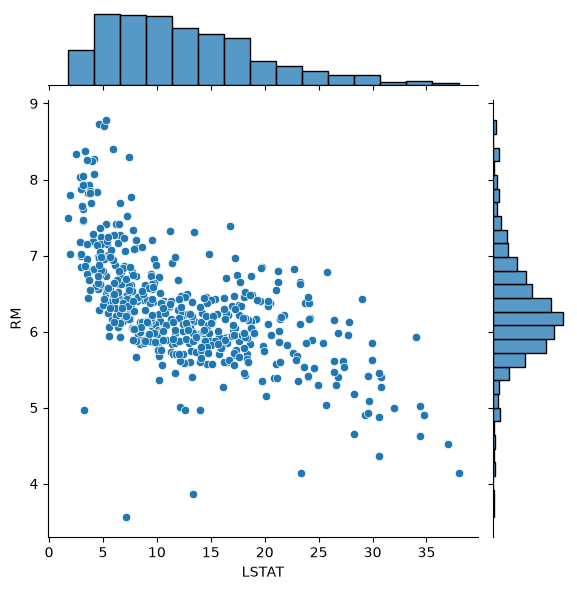

In [29]:
sns.jointplot(
    data=data,
    x="LSTAT",
    y="RM"
)

plt.show()

#### Observations (LSTAT and RM)
<ol>
<li>The majority of rooms per housing unit is 6, and the majority of low-income residents are found in housing units with 1-5 rooms.</li>
<li>On the chart, as the density of low-income earners increases, the number of rooms per house decreases. The fewer the rooms, the lower the value of the homes, the more affordable it becomes for low-income earners, so it's a natural pattern.</li>
</ol>

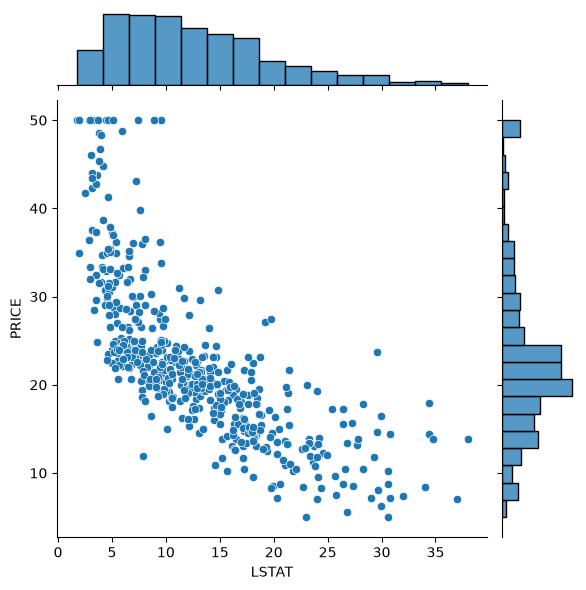

In [30]:
sns.jointplot(
    data=data,
    x="LSTAT",
    y="PRICE"
)

plt.show()

#### Observations (LSTAT and PRICE)
<ol>
<li>Like previously, the chart indicates that as the density of low-income earners increases, the price of houses decreases.</li>
<li>The lower density of low-income earners (1-10) can afford houses of up to $50,000, while the highest density of low-income earners (25-35) can afford house between $10,000-$20,000</li>
</ol>

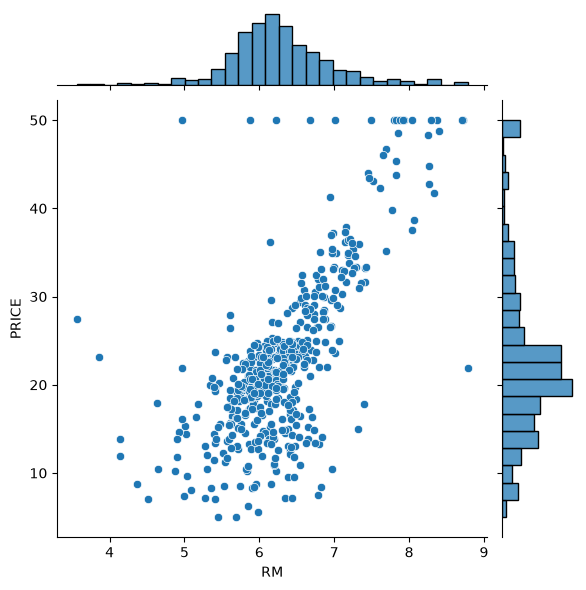

In [31]:
sns.jointplot(
    data=data,
    x="RM",
    y="PRICE"
)

plt.show()

#### Observations (RM and PRICE)
<ol>
<li>The chart indicates that houses with 7-9 rooms can cost up to $50,000, while houses with 4-5 rooms can cost $10,000-$20,000 on average</li>
<li>The higher the rooms, the higher the value of the house, the lower the rooms, the lower the value of the house.</li>
<li><i>We can also see that there are a few houses with 5-6 rooms that cost $50,000. Those may likely be due to other factors like location and access to cleaner air.</i></li>
</ol>

# Split Training & Test Dataset

We *can't* use all 506 entries in our dataset to train our model. The reason is that we want to evaluate our model on data that it hasn't seen yet (i.e., out-of-sample data). That way we can get a better idea of its performance in the real world. 

**Challenge**

* Import the [`train_test_split()` function](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) from sklearn
* Create 4 subsets: X_train, X_test, y_train, y_test
* Split the training and testing data roughly 80/20. 
* To get the same random split every time you run your notebook use `random_state=10`. This helps us get the same results every time and avoid confusion while we're learning. 


Hint: Remember, your **target** is your home PRICE, and your **features** are all the other columns you'll use to predict the price. 


In [36]:
X = data.drop("PRICE", axis=1)
y = data.PRICE

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=10
)

print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(404, 13)
(102, 13)
(404,)
(102,)


# Multivariable Regression

In a previous lesson, we had a linear model with only a single feature (our movie budgets). This time we have a total of 13 features. Therefore, our Linear Regression model will have the following form:

$$ PR \hat ICE = \theta _0 + \theta _1 RM + \theta _2 NOX + \theta _3 DIS + \theta _4 CHAS ... + \theta _{13} LSTAT$$

### Run Your First Regression

**Challenge**

Use sklearn to run the regression on the training dataset. How high is the r-squared for the regression on the training data?

In [39]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-0.13, 0.06,-0.01,...,-0.82, 0.01,-0.58]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['CRIM','ZN','INDUS',...,'PTRATIO','B','LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,36.53
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [41]:
r_squared = model.score(X_train, y_train)

print("R-squared:", r_squared)

R-squared: 0.750121534530608


### Evaluate the Coefficients of the Model

Here we do a sense check on our regression coefficients. The first thing to look for is if the coefficients have the expected sign (positive or negative). 

**Challenge** Print out the coefficients (the thetas in the equation above) for the features. Hint: You'll see a nice table if you stick the coefficients in a DataFrame. 

* We already saw that RM on its own had a positive relation to PRICE based on the scatter plot. Is RM's coefficient also positive?
* What is the sign on the LSAT coefficient? Does it match your intuition and the scatter plot above?
* Check the other coefficients. Do they have the expected sign?
* Based on the coefficients, how much more expensive is a room with 6 rooms compared to a room with 5 rooms? According to the model, what is the premium you would have to pay for an extra room? 

In [46]:
coefficients = pd.DataFrame(
    model.coef_,
    index=X_train.columns,
    columns=["coefficient"]
)

coefficients.sort_values(
    by="coefficient",
    ascending=False
)

,coefficient
RM,3.11
CHAS,1.97
RAD,0.30
ZN,0.06
AGE,0.02
B,0.01
INDUS,-0.01
TAX,-0.01
CRIM,-0.13
LSTAT,-0.58


#### Observations Based on the Coefficient

<p>Based on my trained model's data, here's how each condition affects house pricing:</p>
<ol>
<li>Rm = 3.11. More rooms >>> Higher house price</li>
<li>CHAS = 1.97. Houses closer to Charles river are more expensive. Here's a sneak peek of the river, looks beautiful and clean. Worth it. <br/>
<img src="https://upload.wikimedia.org/wikipedia/commons/5/5a/Charles_River_Esplanade%2C_Boston%2C_Massachusetts.JPG?utm_source=en.wikipedia.org&utm_campaign=index&utm_content=original", width="300"></li>
<li>RAD = 0.30. Better accessibility to radial highways results in higher house prices</li>
<li>ZN = 0.06. More residential zoning results in slightly higher house prices.</li>
<li>Age = 0.02. Older houses may have slighty higher prices</li>
<li>B = 0.01. Higher B variable results in slightly higher house prices</li>
<li>INDUS = -0.01. More industrial lands result in slightly lower house prices.</li>
<li>TAX = -0.01. Higher property tax reuslts in slightlylower house prices</li>
<li>CRIM = -0.13. Higher crime rate results in lower house prices</li>
<li>LSTAT = -0.58. Higher amounts of low income earners results in lower house prices</li>
<li>PTRATIO = -0.82. Higher pupil to teacher ratio results in lower house prices</li>
<li>Dis = -1.48. Higher employment distance results in lower house prices</li>
<li>NOX = -16.27. Higher air polution results in much lower house prices</li>
</ol>

<p>The predicted premium for one extra room is <b>~$3,110</b></p>

### Analyse the Estimated Values & Regression Residuals

The next step is to evaluate our regression. How good our regression is depends not only on the r-squared. It also depends on the **residuals** - the difference between the model's predictions ($\hat y_i$) and the true values ($y_i$) inside `y_train`. 

```
predicted_values = regr.predict(X_train)
residuals = (y_train - predicted_values)
```

**Challenge**: Create two scatter plots.

The first plot should be actual values (`y_train`) against the predicted value values: 

<img src=https://i.imgur.com/YMttBNV.png height=350>

The cyan line in the middle shows `y_train` against `y_train`. If the predictions had been 100% accurate then all the dots would be on this line. The further away the dots are from the line, the worse the prediction was. That makes the distance to the cyan line, you guessed it, our residuals 😊


The second plot should be the residuals against the predicted prices. Here's what we're looking for: 

<img src=https://i.imgur.com/HphsBsj.png height=350>



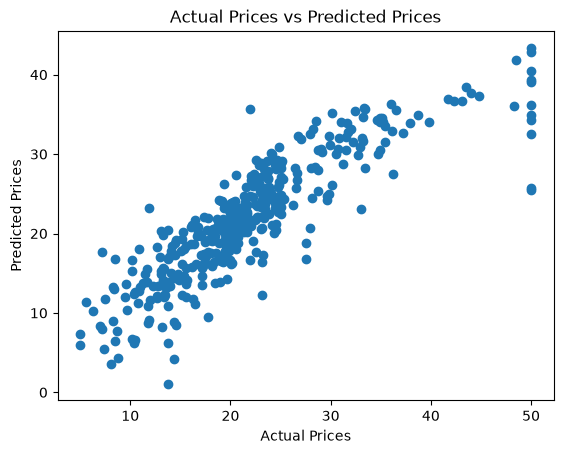

In [48]:
y_pred = model.predict(X_train)

plt.scatter(y_train, y_pred)

plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Actual Prices vs Predicted Prices')

plt.show()

<p>This model's prediction is quite good, but there are a lot of residuals sitiing outside the x/y line. Let's check for the residuals below</p>

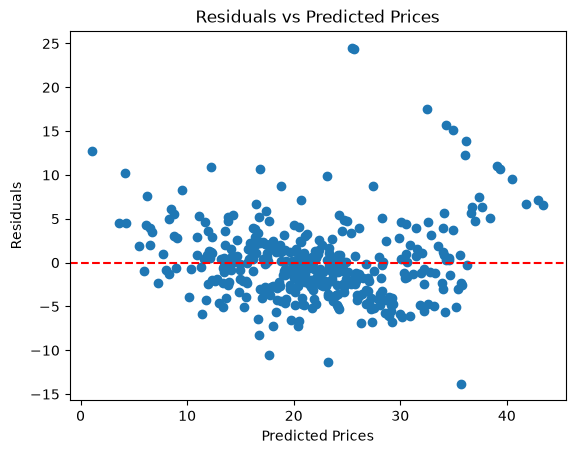

In [49]:
residuals = y_train - y_pred

plt.scatter(y_pred, residuals)

plt.xlabel('Predicted Prices')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Prices')

plt.axhline(y=0, color='red', linestyle='--')

plt.show()

Why do we want to look at the residuals? We want to check that they look random. Why? The residuals represent the errors of our model. If there's a pattern in our errors, then our model has a systematic bias.

We can analyse the distribution of the residuals. In particular, we're interested in the **skew** and the **mean**.

In an ideal case, what we want is something close to a normal distribution. A normal distribution has a skewness of 0 and a mean of 0. A skew of 0 means that the distribution is symmetrical - the bell curve is not lopsided or biased to one side. Here's what a normal distribution looks like: 

<img src=https://i.imgur.com/7QBqDtO.png height=400>

**Challenge**

* Calculate the mean and the skewness of the residuals. 
* Again, use Seaborn's `.displot()` to create a histogram and superimpose the Kernel Density Estimate (KDE)
* Is the skewness different from zero? If so, by how much? 
* Is the mean different from zero?

In [50]:
mean_residuals = residuals.mean()
skewness_residuals = residuals.skew()

print(f"Mean of residuals is: {mean_residuals}")
print(f"Skewness of residuals is: {skewness_residuals}")

Mean of residuals is: -1.5565106959101205e-15
Skewness of residuals is: 1.459442819667964


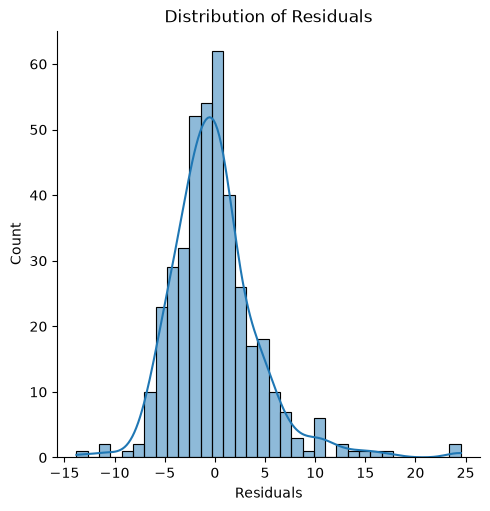

In [52]:
sns.displot(residuals, kde=True)

plt.xlabel('Residuals')
plt.title('Distribution of Residuals')

plt.show()

<p>Most residuals are at 0. This means a lot of house price predictions were actually close.</p>
<p>Skewness is at 1.45. It's positively skewed(towards the right), just as shown in the chart, stretching to 25.</p>

### Data Transformations for a Better Fit

We have two options at this point: 

1. Change our model entirely. Perhaps a linear model is not appropriate. 
2. Transform our data to make it fit better with our linear model. 

Let's try a data transformation approach. 

**Challenge**

Investigate if the target `data['PRICE']` could be a suitable candidate for a log transformation. 

* Use Seaborn's `.displot()` to show a histogram and KDE of the price data. 
* Calculate the skew of that distribution.
* Use [NumPy's `log()` function](https://numpy.org/doc/stable/reference/generated/numpy.log.html) to create a Series that has the log prices
* Plot the log prices using Seaborn's `.displot()` and calculate the skew. 
* Which distribution has a skew that's closer to zero? 


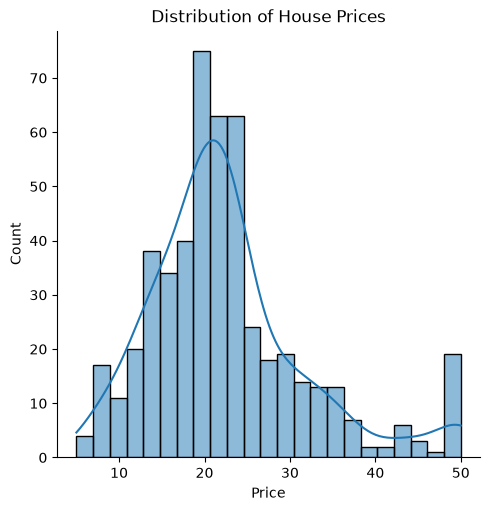

In [55]:
sns.displot(
    data.PRICE,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Price")


plt.show()

In [56]:
price_skew = data.PRICE.skew()

print("Original price skewness:", price_skew)

Original price skewness: 1.1080984082549086


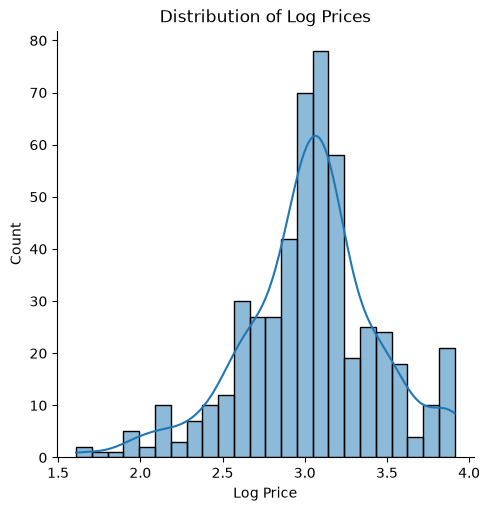

In [60]:
log_prices = np.log(data.PRICE)

sns.displot(log_prices, kde=True)

plt.title("Distribution of Log Prices")
plt.xlabel("Log Price")

plt.show()

In [59]:
log_price_skew = log_prices.skew()

print("Original skewness:", price_skew)
print("Log price skewness:", log_price_skew)

Original skewness: 1.1080984082549086
Log price skewness: -0.33032129530987964


<p>As we can see above, log transformation changed the skewness from 1.1 to -0.3(which is much closer to 0).</p>

#### How does the log transformation work?

Using a log transformation does not affect every price equally. Large prices are affected more than smaller prices in the dataset. Here's how the prices are "compressed" by the log transformation:

<img src=https://i.imgur.com/TH8sK1Q.png height=200>

We can see this when we plot the actual prices against the (transformed) log prices. 

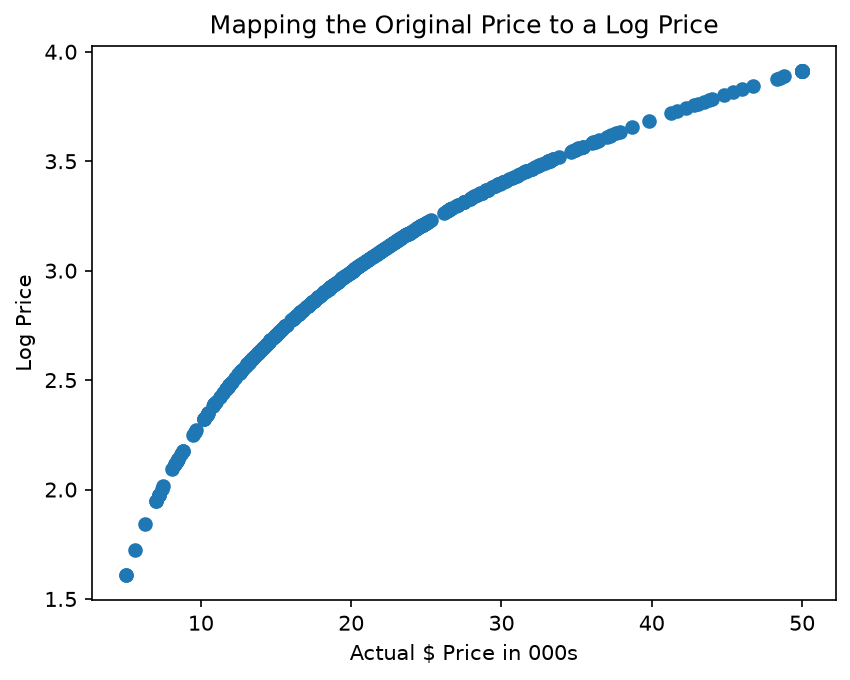

In [61]:
plt.figure(dpi=150)
plt.scatter(data.PRICE, np.log(data.PRICE))

plt.title('Mapping the Original Price to a Log Price')
plt.ylabel('Log Price')
plt.xlabel('Actual $ Price in 000s')
plt.show()

## Regression using Log Prices

Using log prices instead, our model has changed to:

$$ \log (PR \hat ICE) = \theta _0 + \theta _1 RM + \theta _2 NOX + \theta_3 DIS + \theta _4 CHAS + ... + \theta _{13} LSTAT $$

**Challenge**: 

* Use `train_test_split()` with the same random state as before to make the results comparable. 
* Run a second regression, but this time use the transformed target data. 
* What is the r-squared of the regression on the training data? 
* Have we improved the fit of our model compared to before based on this measure?


In [63]:
X = data.drop("PRICE", axis=1)
y = log_prices

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=10
)

In [65]:
log_model = LinearRegression()

log_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-0.01, 0. , 0. ,...,-0.03, 0. ,-0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['CRIM','ZN','INDUS',...,'PTRATIO','B','LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [66]:
log_r_squared = log_model.score(X_train, y_train)

print(f"R_squared: {log_r_squared}")

R_squared: 0.7930234826697583


<p>The model's fit has been succesfully improved. The original model had an R_squared of 0.7501, while the new one has an R_squared of 0.7930. That's 75% vs 79%. The new model explains more variation in house prices than the previous one.</p>

## Evaluating Coefficients with Log Prices

**Challenge**: Print out the coefficients of the new regression model. 

* Do the coefficients still have the expected sign? 
* Is being next to the river a positive based on the data?
* How does the quality of the schools affect property prices? What happens to prices as there are more students per teacher? 

Hint: Use a DataFrame to make the output look pretty. 

In [ ]:
log_coefficients = pd.DataFrame(
    data=log_model.coef_,
    index=X_train.columns,
    columns=["coefficient"]
)

In [71]:
log_coefficients.sort_values(
    by="coefficient",
    ascending=False
)

,coefficient
CHAS,0.08
RM,0.07
RAD,0.01
INDUS,0.00
ZN,0.00
AGE,0.00
B,0.00
TAX,-0.00
CRIM,-0.01
LSTAT,-0.03


<p>CHAS, RM, RAD, INDUS, ZN, AGE and B have positive coefficients with house prices.</p>
<p>TAX, CRIM, LSTAT, PTRATIO, DIS and NOX have negative coefficients with house prices. <i>Remember the zero values have small hidden values.</i></p>

## Regression with Log Prices & Residual Plots

**Challenge**: 

* Copy-paste the cell where you've created scatter plots of the actual versus the predicted home prices as well as the residuals versus the predicted values. 
* Add 2 more plots to the cell so that you can compare the regression outcomes with the log prices side by side. 
* Use `indigo` as the colour for the original regression and `navy` for the color using log prices.

In [72]:
y_train_original = data.loc[y_train.index, "PRICE"]

y_pred = model.predict(X_train)

y_log_pred = log_model.predict(X_train)

residuals = y_train_original - y_pred
log_residuals = y_train - y_log_pred

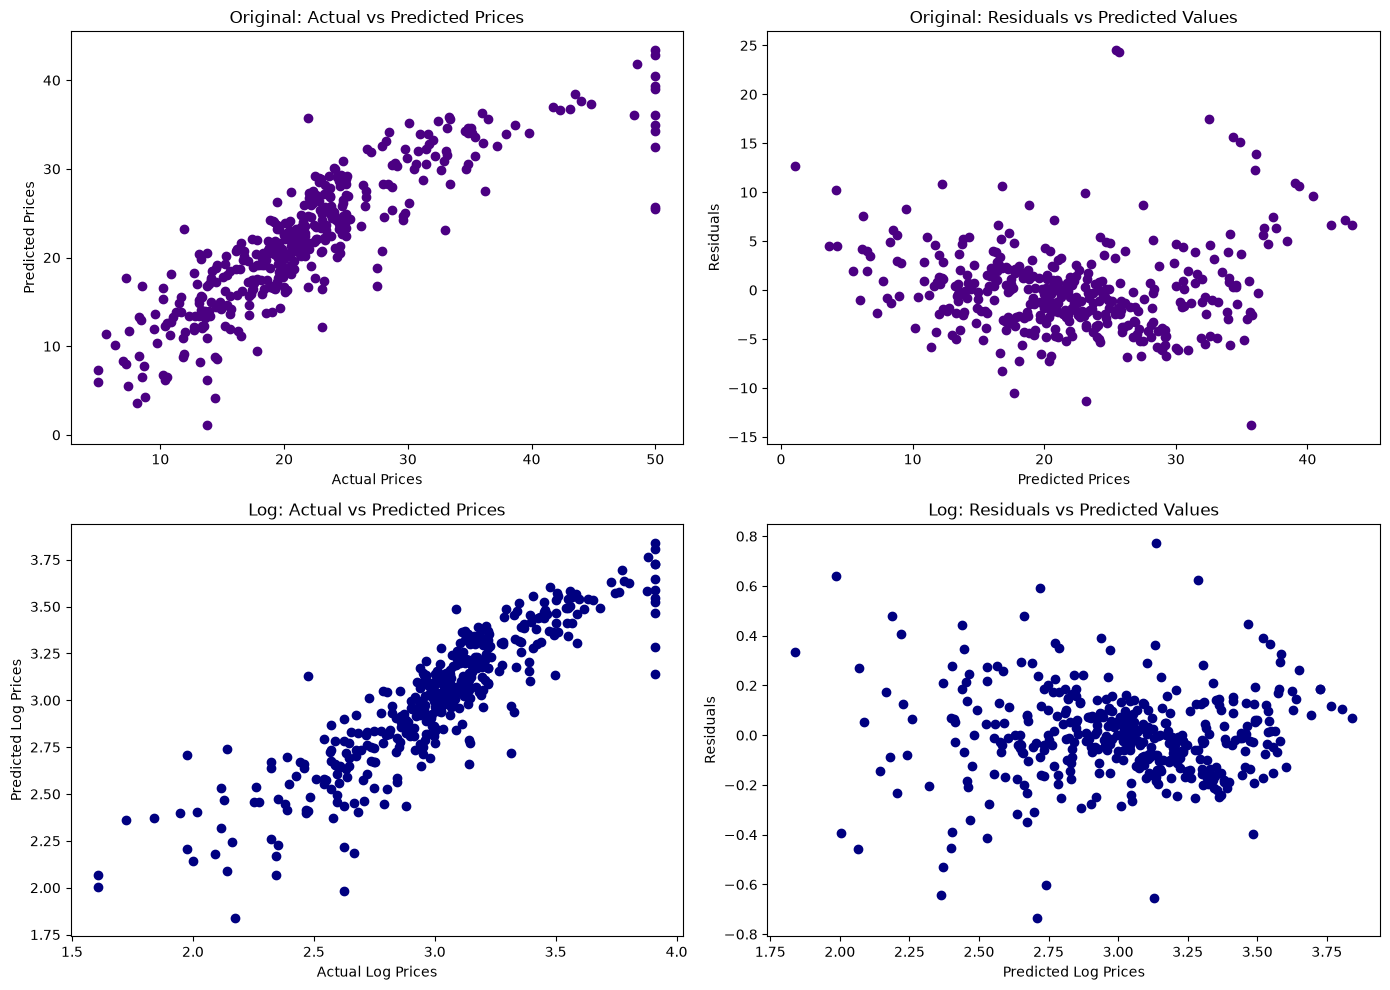

In [73]:
plt.figure(figsize=(14, 10))

# 1. Original: Actual vs Predicted
plt.subplot(2, 2, 1)
plt.scatter(y_train_original, y_pred, color='indigo')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Original: Actual vs Predicted Prices')

# 2. Original: Residuals vs Predicted
plt.subplot(2, 2, 2)
plt.scatter(y_pred, residuals, color='indigo')
plt.xlabel('Predicted Prices')
plt.ylabel('Residuals')
plt.title('Original: Residuals vs Predicted Values')

# 3. Log: Actual vs Predicted
plt.subplot(2, 2, 3)
plt.scatter(y_train, y_log_pred, color='navy')
plt.xlabel('Actual Log Prices')
plt.ylabel('Predicted Log Prices')
plt.title('Log: Actual vs Predicted Prices')

# 4. Log: Residuals vs Predicted
plt.subplot(2, 2, 4)
plt.scatter(y_log_pred, log_residuals, color='navy')
plt.xlabel('Predicted Log Prices')
plt.ylabel('Residuals')
plt.title('Log: Residuals vs Predicted Values')

plt.tight_layout()
plt.show()

##### This shows a comparison shows the Actual prices vs Predicted prices (Both original and log).
<p>In the original, we can see the x,y line isn't straight, as the model sometimes overpredicts cheap and underpredicts expensive homes. It leaves very unbalanced residuals.</p>
<p>This model fits along the x/y diagonal line more tighly and evenly.</p>

**Challenge**: 

Calculate the mean and the skew for the residuals using log prices. Are the mean and skew closer to 0 for the regression using log prices?

In [75]:
print(f"Mean of log residuals: {log_residuals.mean()}")
print(f"Skew of log residuals: {log_residuals.skew()}")

Mean of log residuals: 1.8192268373808257e-16
Skew of log residuals: 0.09299942594122027


<p>The mean is close to zero, this notation(1.8192268373808257e-16) is extremely close to zero, meaning the model's prediction errors are balanced out</p>
<p>The skew is extremely close to zero this time, which means the residual distribution is almost symentrical.</p>

# Compare Out of Sample Performance

The *real* test is how our model performs on data that it has not "seen" yet. This is where our `X_test` comes in. 

**Challenge**

Compare the r-squared of the two models on the test dataset. Which model does better? Is the r-squared higher or lower than for the training dataset? Why?

In [78]:
# Original model
original_test_r2 = model.score(X_test, data.loc[y_test.index, "PRICE"])

# Log-transformed model
log_test_r2 = log_model.score(X_test, y_test)

print(f"Original Model Test R-squared: {original_test_r2}")
print(f"Log Model Test R-squared: {log_test_r2}")

Original Model Test R-squared: 0.6709339839115627
Log Model Test R-squared: 0.7446922306260728


<p>The log transformed model generally performs better with a test R-squared of 0.7447 compared to 0.6709 for the original model. This model performs better on unseen data.</p>

# Predict a Property's Value using the Regression Coefficients

Our preferred model now has an equation that looks like this:

$$ \log (PR \hat ICE) = \theta _0 + \theta _1 RM + \theta _2 NOX + \theta_3 DIS + \theta _4 CHAS + ... + \theta _{13} LSTAT $$

The average property has the mean value for all its charactistics:

In [79]:
# Starting Point: Average Values in the Dataset
features = data.drop(['PRICE'], axis=1)
average_vals = features.mean().values
property_stats = pd.DataFrame(data=average_vals.reshape(1, len(features.columns)), 
                              columns=features.columns)
property_stats

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,3.61,11.36,11.14,0.07,0.55,6.28,68.57,3.80,9.55,408.24,18.46,356.67,12.65


**Challenge**

Predict how much the average property is worth using the stats above. What is the log price estimate and what is the dollar estimate? You'll have to [reverse the log transformation with `.exp()`](https://numpy.org/doc/stable/reference/generated/numpy.exp.html?highlight=exp#numpy.exp) to find the dollar value. 

In [80]:
log_estimate = log_model.predict(property_stats)
print(f"Log price estimate: {log_estimate[0]}")

Log price estimate: 3.0302872305633954


In [81]:
dollar_estimate = np.exp(log_estimate)
print(f"Estimated property price: ${dollar_estimate[0]:,.2f}")

Estimated property price: $20.70


<p>The predicted log price of of an average property is 3.0303. After reversing the log transformation, the estimated property value is $20.70(thousands, [$20,700]).</p>

**Challenge**

Keeping the average values for CRIM, RAD, INDUS and others, value a property with the following characteristics:

In [82]:
# Define Property Characteristics
next_to_river = True
nr_rooms = 8
students_per_classroom = 20 
distance_to_town = 5
pollution = data.NOX.quantile(q=0.75) # high
amount_of_poverty =  data.LSTAT.quantile(q=0.25) # low

In [83]:
# Solution:
property_stats.CHAS = int(next_to_river)
property_stats.RM = nr_rooms
property_stats.PTRATIO = students_per_classroom
property_stats.DIS = distance_to_town
property_stats.NOX = pollution
property_stats.LSTAT = amount_of_poverty


In [84]:
new_log_estimate = log_model.predict(property_stats)
new_dollar_estimate = np.exp(new_log_estimate)

print(f"Log price estimate: {new_log_estimate[0]}")
print(f"Estimated property price: ${new_dollar_estimate[0] * 1000:,.2f}")

Log price estimate: 3.25006536944092
Estimated property price: $25,792.03


<p>This customised property is valued at approximately $25,792.03.</p>